# Core pilot: verified tracking to baseline evaluation

This is a real executed **descriptive** forecast snapshot. It reads one explicit immutable schema-2 handoff; it does not retrain models, inspect future periods or load model pickles. The preceding notebook covers Reddit preparation/detection.

From the repository root install `python -m pip install -e ".[graph,forecast,notebook]"`, download raw files using Git LFS, and run `python -m reddit_sna week1 --config configs/core.toml --run-id week1-demo`. Choose the project `.venv` kernel, then **Restart Kernel > Run All**. Use a new ID if that output already exists. GitHub only displays this saved execution; cells run in VS Code/Jupyter.

Set `REDDIT_FORECAST_RUN` to a different forecast directory below `artifacts/`, relative to that directory (for example `core/my-demo/forecast`). No automatic local run discovery is performed. See `docs/RUNBOOK.md`.

In [1]:
# Resolve the package and project without sys.path edits or notebook installs.
import os
import sys
from pathlib import Path
from IPython.display import display, Markdown
if sys.version_info < (3, 11):
    raise RuntimeError("Select the project's Python 3.11+ .venv kernel")
try:
    from reddit_sna.reporting.forecast import summarize, build_figures, export_report
except ImportError as exc:
    raise RuntimeError('Use this kernel to install: python -m pip install -e ".[forecast,notebook]"') from exc
project_hint = os.environ.get("REDDIT_SNA_PROJECT")
root = Path(project_hint).resolve() if project_hint else next((p for p in (Path.cwd(), *Path.cwd().parents) if (p / "pyproject.toml").exists() and (p / "configs/core.toml").exists()), None)
if root is None:
    raise RuntimeError("Open the project folder or set REDDIT_SNA_PROJECT")
artifact_root = (root / "artifacts").resolve()
run = (artifact_root / os.environ.get("REDDIT_FORECAST_RUN", "core/week1-demo/forecast")).resolve()
if not run.is_relative_to(artifact_root) or run == artifact_root:
    raise ValueError("Select a forecast run below project artifacts")
if not (run / "manifest.json").exists():
    raise RuntimeError("Run the documented week1 command, or select an explicit completed forecast run")
print("Active Python:", sys.executable)
print("Selected forecast:", run.relative_to(root))

Active Python: <PROJECT_ROOT>\.venv\Scripts\python.exe
Selected forecast: artifacts\core\week1-group-core-001\forecast


## Provenance and operational target

GED here is a declared strength/topology adaptation, not the original social-position method. Both directional inclusion thresholds are 0.5; dissolve threshold is 0.1. Ambiguous/weak cases remain unresolved. Labels describe the tracker rule rather than independent social events. Features are known through t; labels concern t→t+1. Scaler/model fitting uses only training label months. The last snapshot has features but no invented future label.

In [2]:
# All plotted data pass independent hash, join, support and metric checks first.
report = summarize(run)
delivery = report["delivery"]
manifest = delivery["manifest"]
display({"forecast_manifest_sha256": report["manifest_sha256"], "label_reference_id": manifest["label_reference_id"],
         "months": manifest["actual_months"], "tracker": manifest["tracker_config"],
         "feature_order": manifest["features"], "test_start_label_month": manifest["test_start_label_month"],
         "environment": manifest["dependencies"], "label_truth": manifest["label_truth"]})
display({"coverage": report["coverage"], "train": delivery["metrics"]["train_samples"], "test": delivery["metrics"]["test_samples"]})

{'forecast_manifest_sha256': '9f40a4fb278f78b64807d72486c1502f74bc6744c3e4ee52957b9ebe7f54406e',
 'label_reference_id': '162177aef0640eacbc19e0004f5b176d75e242e3c968418bcc7b32c90824f22e',
 'months': ['2015-01',
  '2015-02',
  '2015-03',
  '2015-04',
  '2015-05',
  '2015-06',
  '2015-07',
  '2015-08',
  '2015-09',
  '2015-10',
  '2015-11',
  '2015-12'],
 'tracker': {'method': 'ged-strength-topology-v1',
  'alpha': 0.5,
  'beta': 0.5,
  'dissolve': 0.1,
  'numeric_tolerance': 1e-12,
  'importance': 'internal_weighted_degree_zero_fallback_unit'},
 'feature_order': ['size',
  'internal_edges',
  'internal_weight',
  'boundary_weight',
  'density',
  'community_age',
  'history_missing',
  'predecessor_count',
  'past_growth',
  'past_retention',
  'inflow_fraction',
  'outflow_fraction'],
 'test_start_label_month': '2015-10',
 'environment': {'scikit-learn': '1.9.1',
  'numpy': '2.5.4',
  'scipy': '1.18.1',
  'joblib': '1.6.0'},
 'label_truth': 'tracker-derived pseudo-labels, not social gr

{'coverage': {'total_transitions': 2065,
  'eligible': 1333,
  'excluded': 732,
  'exclusion_fraction': 0.35447941888619855},
 'train': 762,
 'test': 571}

## Class support and coverage

Read zero-support classes and excluded cases before reading aggregate scores. Stratified labels and exclusions are different populations; changing the tracker/reference changes the forecasting task. Missing classes receive zero F1 in the fixed six-class average.

[{'event': 'stable', 'train': 1, 'test': 0},
 {'event': 'grow', 'train': 10, 'test': 8},
 {'event': 'shrink', 'train': 20, 'test': 12},
 {'event': 'merge', 'train': 38, 'test': 20},
 {'event': 'split', 'train': 22, 'test': 6},
 {'event': 'dissolve', 'train': 671, 'test': 525}]

[{'model': 'majority',
  'macro_f1': 0.15967153284671534,
  'balanced_accuracy_present_classes': 0.2},
 {'model': 'logistic_regression',
  'macro_f1': 0.36054044653144635,
  'balanced_accuracy_present_classes': 0.48219047619047617}]

{'exclusion_reasons': {'weak_overlap_unresolved': 732},
 'dominant_test_fraction': 0.9194395796847635,
 'absent_test_classes': ['stable']}

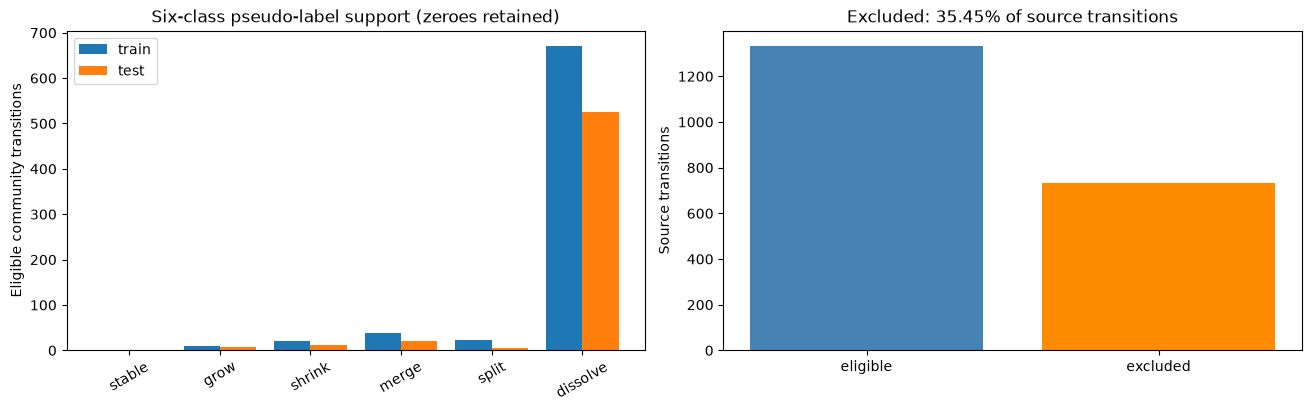

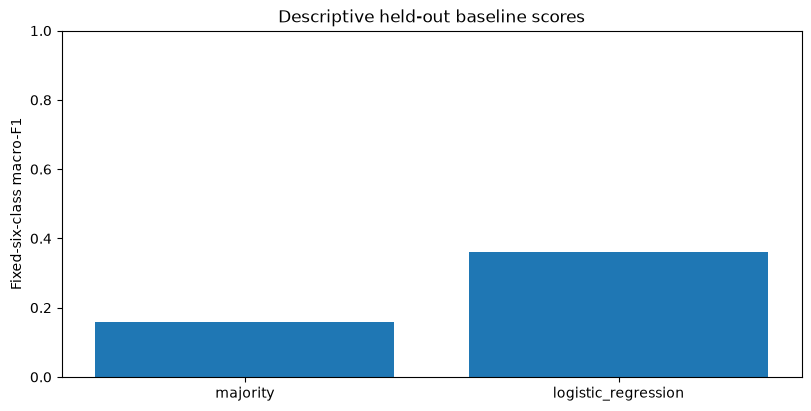

In [3]:
# Tables keep all six events, even absent classes.
display(report["classes"])
display(report["models"])
display({"exclusion_reasons": delivery["quality"]["exclusion_reasons"],
         "dominant_test_fraction": delivery["quality"]["dominant_test_fraction"],
         "absent_test_classes": delivery["quality"]["absent_test_classes"]})
import matplotlib.pyplot as plt
plt.ioff()
figures = build_figures(report)
# Detach every figure from inline auto-display; show each retained object once.
for figure in figures.values():
    plt.close(figure)
for name in ("support_and_coverage", "baseline_scores"):
    display(figures[name])
    plt.close(figures[name])

## Confusion matrices and class-level failures

Rows are tracker pseudo-labels and columns are model predictions. A high dominant-class score does not demonstrate useful grow/merge/stable prediction. Zero support is lack of evaluation evidence, not a successful zero-error class.

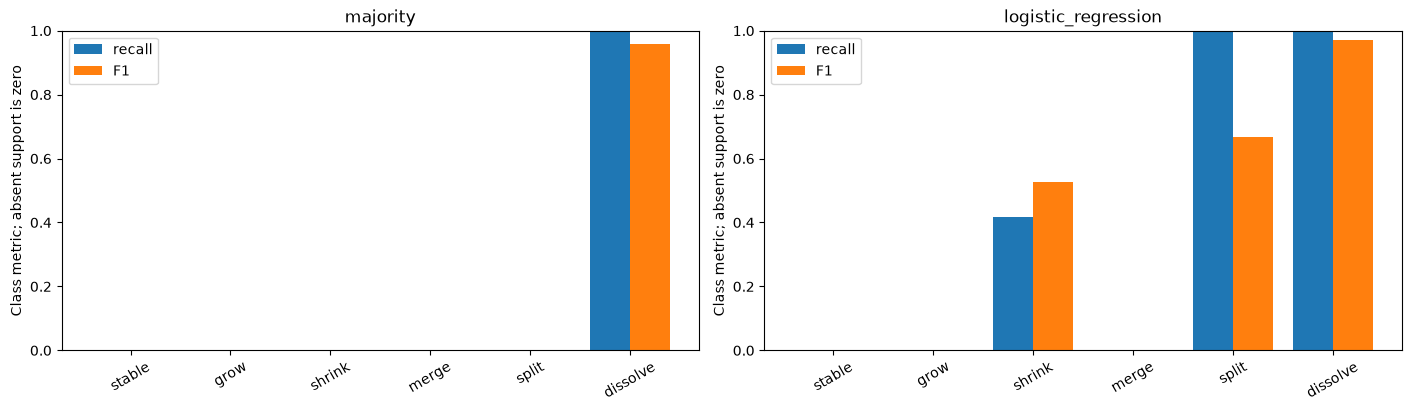

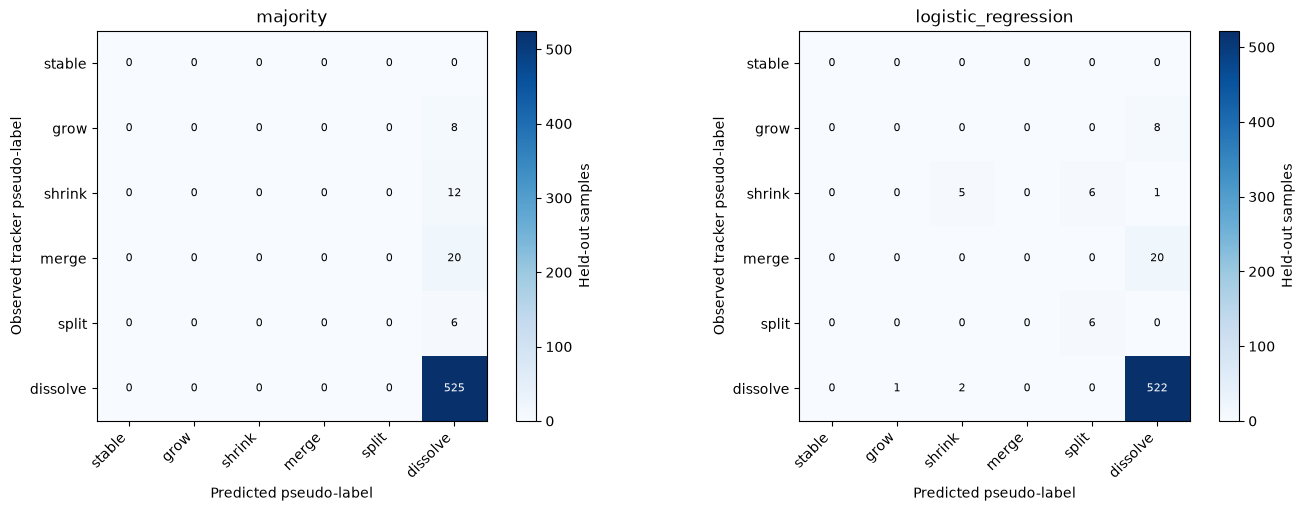

{'model': 'majority',
 'per_class': {'stable': {'precision': 0.0,
   'recall': 0.0,
   'f1-score': 0.0,
   'support': 0.0},
  'grow': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 8.0},
  'shrink': {'precision': 0.0,
   'recall': 0.0,
   'f1-score': 0.0,
   'support': 12.0},
  'merge': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 20.0},
  'split': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 6.0},
  'dissolve': {'precision': 0.9194395796847635,
   'recall': 1.0,
   'f1-score': 0.958029197080292,
   'support': 525.0}}}

{'model': 'logistic_regression',
 'per_class': {'stable': {'precision': 0.0,
   'recall': 0.0,
   'f1-score': 0.0,
   'support': 0.0},
  'grow': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 8.0},
  'shrink': {'precision': 0.7142857142857143,
   'recall': 0.4166666666666667,
   'f1-score': 0.5263157894736842,
   'support': 12.0},
  'merge': {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 20.0},
  'split': {'precision': 0.5,
   'recall': 1.0,
   'f1-score': 0.6666666666666666,
   'support': 6.0},
  'dissolve': {'precision': 0.9473684210526315,
   'recall': 0.9942857142857143,
   'f1-score': 0.9702602230483272,
   'support': 525.0}}}

In [4]:
for name in ("per_class_metrics", "confusion_matrices"):
    display(figures[name])
    plt.close(figures[name])
for name, metrics in delivery["metrics"]["models"].items():
    display({"model": name, "per_class": {label: metrics["per_class"][label] for label in metrics["labels"]}})

## Time and development diagnostics

Development folds use expanding training-only label months. Monthly held-out scores are descriptive diagnostics, not independent repeats or a confidence interval. The 2015 period was already inspected during development and is not a fresh confirmatory test.

[{'model': 'majority',
  'label_month': '2015-10',
  'samples': 167,
  'macro_f1': 0.1571729957805907},
 {'model': 'majority',
  'label_month': '2015-11',
  'samples': 237,
  'macro_f1': 0.16122004357298475},
 {'model': 'majority',
  'label_month': '2015-12',
  'samples': 167,
  'macro_f1': 0.15991692627206647},
 {'model': 'logistic_regression',
  'label_month': '2015-10',
  'samples': 167,
  'macro_f1': 0.41854838709677417},
 {'model': 'logistic_regression',
  'label_month': '2015-11',
  'samples': 237,
  'macro_f1': 0.3542682926829268},
 {'model': 'logistic_regression',
  'label_month': '2015-12',
  'samples': 167,
  'macro_f1': 0.2841269841269841}]

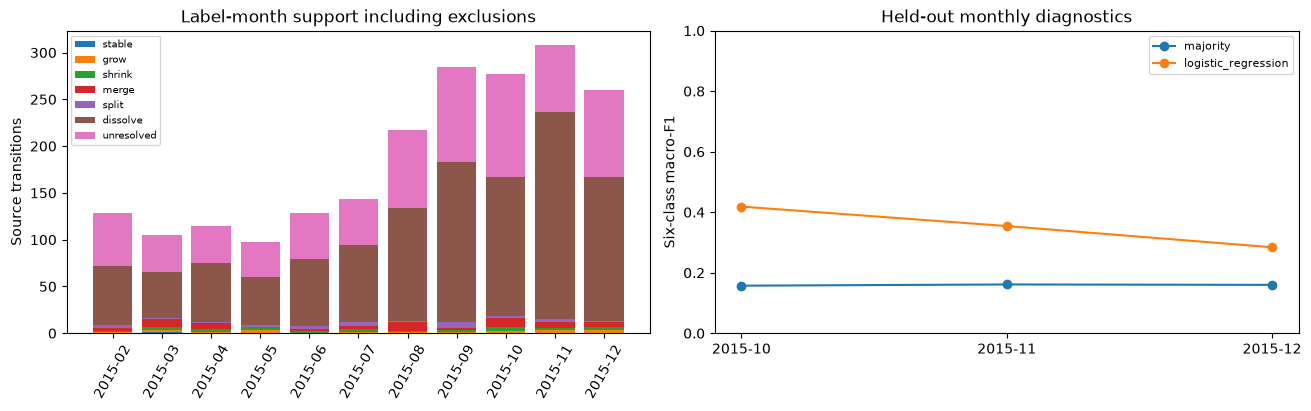

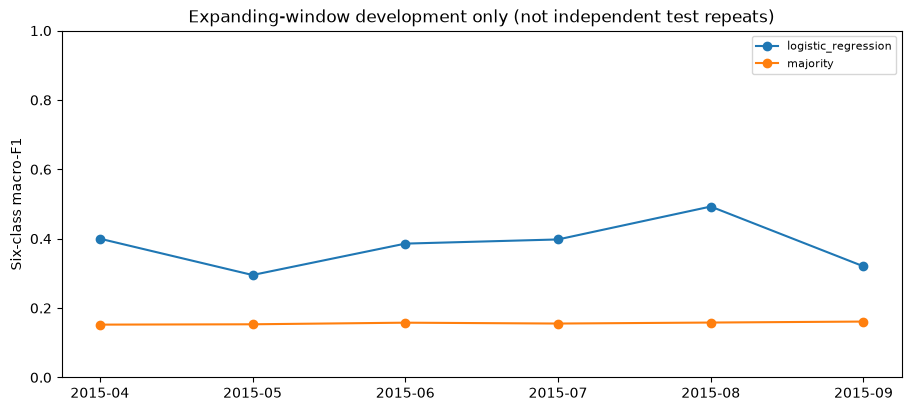

In [5]:
display(report["monthly_scores"])
for name in ("monthly_diagnostics", "development_folds"):
    display(figures[name])
    plt.close(figures[name])

## Specific prediction errors

These rows are actual saved model errors, not hand-entered demonstration predictions. Community identifiers are local to this cohort/month and do not identify a stable social group. Keep label_reference_id with any downstream comparison.

In [6]:
# Show a bounded deterministic subset; the verified errors.csv retains all errors.
for name in sorted(delivery["metrics"]["models"]):
    errors = [row for row in delivery["errors"] if row["model"] == name]
    display({"model": name, "error_count": len(errors), "first_errors": errors[:5]})

{'model': 'logistic_regression',
 'error_count': 38,
 'first_errors': [{'reference_id': 'week1-demo-input:reply-r-v3-order1:985fb8e035ef51d69ef2b22c343c047d1302a6bc6b8fbba1d0e641b51d8f14de:leiden-rb-v2-gamma1-seed0',
   'feature_month': '2015-09',
   'community_id': 'c1',
   'label_month': '2015-10',
   'model': 'logistic_regression',
   'y_true': 'shrink',
   'y_pred': 'split'},
  {'reference_id': 'week1-demo-input:reply-r-v3-order1:985fb8e035ef51d69ef2b22c343c047d1302a6bc6b8fbba1d0e641b51d8f14de:leiden-rb-v2-gamma1-seed0',
   'feature_month': '2015-09',
   'community_id': 'c126',
   'label_month': '2015-10',
   'model': 'logistic_regression',
   'y_true': 'merge',
   'y_pred': 'dissolve'},
  {'reference_id': 'week1-demo-input:reply-r-v3-order1:985fb8e035ef51d69ef2b22c343c047d1302a6bc6b8fbba1d0e641b51d8f14de:leiden-rb-v2-gamma1-seed0',
   'feature_month': '2015-09',
   'community_id': 'c164',
   'label_month': '2015-10',
   'model': 'logistic_regression',
   'y_true': 'merge',
   'y_p

{'model': 'majority',
 'error_count': 46,
 'first_errors': [{'reference_id': 'week1-demo-input:reply-r-v3-order1:985fb8e035ef51d69ef2b22c343c047d1302a6bc6b8fbba1d0e641b51d8f14de:leiden-rb-v2-gamma1-seed0',
   'feature_month': '2015-09',
   'community_id': 'c0',
   'label_month': '2015-10',
   'model': 'majority',
   'y_true': 'split',
   'y_pred': 'dissolve'},
  {'reference_id': 'week1-demo-input:reply-r-v3-order1:985fb8e035ef51d69ef2b22c343c047d1302a6bc6b8fbba1d0e641b51d8f14de:leiden-rb-v2-gamma1-seed0',
   'feature_month': '2015-09',
   'community_id': 'c1',
   'label_month': '2015-10',
   'model': 'majority',
   'y_true': 'shrink',
   'y_pred': 'dissolve'},
  {'reference_id': 'week1-demo-input:reply-r-v3-order1:985fb8e035ef51d69ef2b22c343c047d1302a6bc6b8fbba1d0e641b51d8f14de:leiden-rb-v2-gamma1-seed0',
   'feature_month': '2015-09',
   'community_id': 'c10',
   'label_month': '2015-10',
   'model': 'majority',
   'y_true': 'shrink',
   'y_pred': 'dissolve'},
  {'reference_id': 'week

## Export and independent review

Standalone figures and the blinded review package remain local. To export a new source-bound figure set, set `REDDIT_FORECAST_EXPORT` to a new directory relative to `artifacts/`; the default replay writes nothing. Use `review-labels` and the annotation protocol for independent review. An annotation template is not completed validation, and membership evidence does not establish social truth.

In [7]:
export_name = os.environ.get("REDDIT_FORECAST_EXPORT")
if export_name:
    exported = export_report(run, artifact_root / export_name, artifact_root)
    print("Verified report export:", exported.relative_to(root))
else:
    print("Read-only replay complete; export not requested")

Read-only replay complete; export not requested


## Acceptance and remaining scientific work

The engineering demo connects Reddit inputs to evaluation without other pairs' outputs. It does not establish a guaranteed grade or paper novelty. Preserve negative results, unsupported classes and exclusions. Two reviewers still need to annotate blinded cases and resolve disagreement; a coordinator must freeze a protocol and confirm a genuinely untouched future period before confirmatory evaluation. Full original GED, HeTCo and temporal/heterogeneous detection belong to later research work. See `docs/LABEL_REVIEW.md`, `reports/WEEK1_REPORT.md#113-research-decision` and `docs/RESULTS.md#presentation-outline`.